# Tutorial: predict unmeasured genes in a fetal-heart MERFISH section

This notebook downloads a small public dataset, fits RESONATE on a CPU, checks it on measured genes hidden from the
model, and predicts genes that the panel did not measure. The outputs below come from one run of this notebook, top to
bottom, in a new environment on 4 CPU cores; the run took 7.5 minutes. Download it (button at the top of the page, or
[from GitHub](https://github.com/J041120h/RESONATE_tutorial/blob/main/docs/tutorials/walkthrough.ipynb)) and run it in an
empty folder after installing RESONATE ([Installation](https://j041120h.github.io/RESONATE_tutorial/installation/)):

```bash
pip install torch --index-url https://download.pytorch.org/whl/cpu
pip install "resonate-st[notebook] @ git+https://github.com/J041120h/RESONATE.git"
```

## 1. Load the demo data

`fetal_heart_demo` downloads the demo files (about 12 MB) into `data/`, checks their checksums and loads them: a MERFISH
window of a 13-week fetal heart (236 measured genes), a single-cell reference of the same study, one scGPT-spatial
embedding per gene, and 48 panel genes to hide from the model.

In [1]:
import matplotlib.pyplot as plt
import resonate

plt.rcParams["figure.dpi"] = 80
spatial, reference, embeddings, held_out = resonate.datasets.fetal_heart_demo("data")
print(spatial, reference, sep="\n\n")

data/fetal_heart_reference.h5ad: OK (downloaded)
data/fetal_heart_spatial.h5ad: OK (downloaded)
data/held_out_genes.txt: OK (downloaded)
data/sample_info.json: OK (downloaded)
data/scgpt_spatial_embeddings_subset.npz: OK (downloaded)
AnnData object with n_obs × n_vars = 12000 × 236
    obs: 'section', 'stage', 'author_fine', 'split', 'cell_group'
    obsm: 'spatial'

AnnData object with n_obs × n_vars = 8011 × 2244
    obs: 'donor', 'author_label'


## 2. Look at the section

The authors' cell types, grouped into eight groups (`obs["cell_group"]`). RESONATE does not use them; they help to read
the maps below.

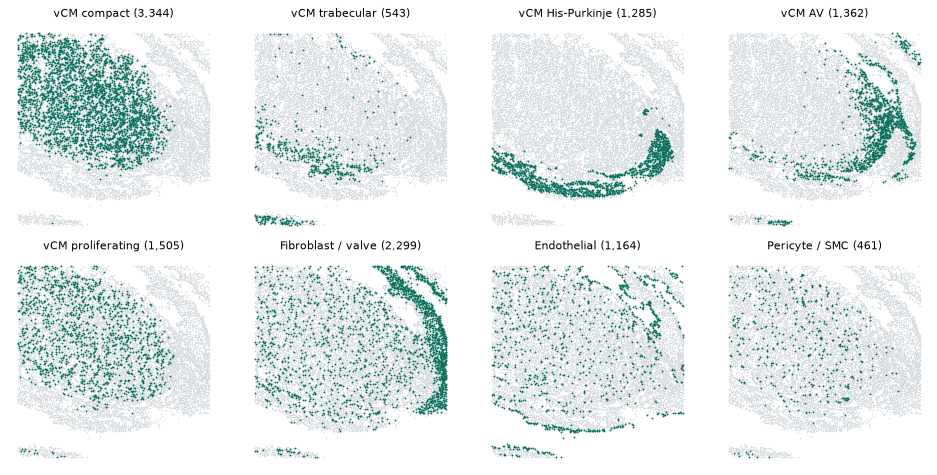

In [2]:
resonate.pl.cell_types(spatial, "cell_group")

## 3. Impute

One call prepares the inputs, trains the model (first on the reference, then on the spatial cells) and predicts.
`heldout=` hides the 48 panel genes from the model so that we can score them; `genes=` lists genes the panel never
measured. `device="cpu", max_epochs=12` keeps the run to minutes on a laptop.

In [3]:
markers = ["NPPA", "NPPB", "MYL2", "MYL3", "FHL2", "OGN", "COL6A2", "MFAP4", "CDH5", "EGFL7", "EMCN",
           "NDUFA4L2", "COX4I2"]
pred, model = resonate.impute(spatial, reference, embeddings, genes=markers, heldout=held_out,
                              device="cpu", max_epochs=12, return_model=True)
pred

23:59:56 panel 249 genes = 188 measured + 61 targets (48 held out from the input)
23:59:56 12000 spatial cells (9600/1265/1135 train/val/test), 8011 reference cells, 4 reference batch(es), device cpu
23:59:58   lookup fold 1/20
23:59:58   lookup fold 2/20
23:59:58   lookup fold 3/20
23:59:59   lookup fold 4/20
23:59:59   lookup fold 5/20
00:00:00   lookup fold 6/20
00:00:00   lookup fold 7/20
00:00:00   lookup fold 8/20
00:00:01   lookup fold 9/20
00:00:01   lookup fold 10/20
00:00:02   lookup fold 11/20
00:00:02   lookup fold 12/20
00:00:02   lookup fold 13/20
00:00:03   lookup fold 14/20
00:00:03   lookup fold 15/20
00:00:04   lookup fold 16/20
00:00:04   lookup fold 17/20
00:00:04   lookup fold 18/20
00:00:05   lookup fold 19/20
00:00:05   lookup fold 20/20
00:00:05 reference cell types (Leiden on Harmony-corrected reference)
00:00:18   leiden resolution 1.0250 -> 24 clusters
00:00:18   leiden resolution 0.5375 -> 18 clusters
00:00:18 type-specific correlations
00:00:18 reference vo

AnnData object with n_obs × n_vars = 12000 × 61
    obs: 'split'
    var: 'is_fit_target', 'heldout'
    uns: 'resonate'
    obsm: 'spatial'

## 4. Score the held-out genes

Pearson correlation between predicted and measured values in the test cells, which were not used for training.
`top_n` marks the genes detected in at least 10 % of cells, the set used in the paper.

mean Pearson over the top_n genes: 0.386


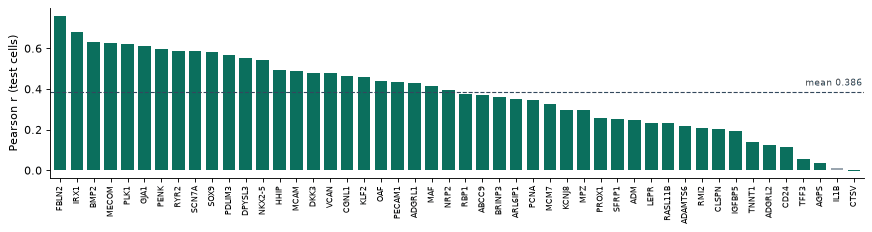

In [4]:
scores = resonate.score(pred, spatial)
print("mean Pearson over the top_n genes:", round(scores.loc[scores.top_n, "pearson"].mean(), 3))
resonate.pl.gene_scores(scores)

## 5. Measured and predicted maps

The four held-out genes that RESONATE predicts best. As in the paper, each prediction is shown rank-matched to the
measured values of the same gene, so both rows share one colour scale (clipped to the measured 1st-99th percentile);
r is computed on the raw predictions.

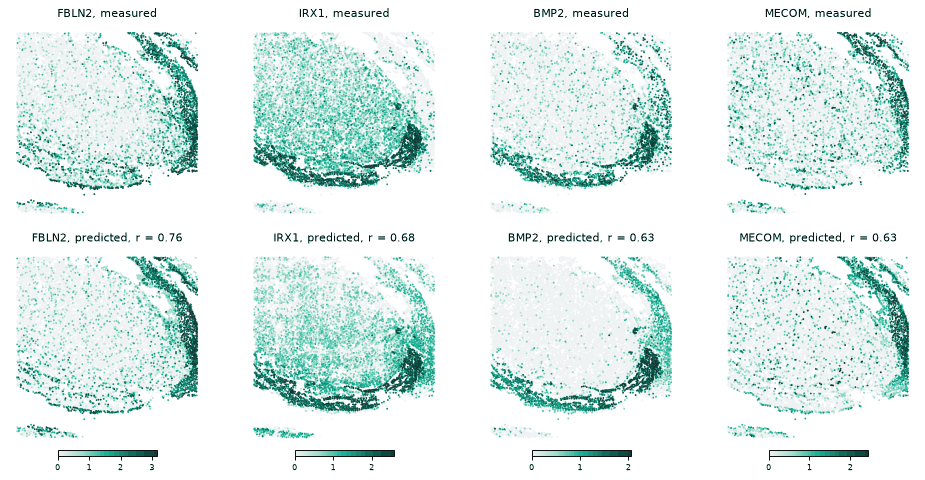

In [5]:
resonate.pl.spatial_compare(pred, spatial, scores[scores.top_n].index[:4], table=scores)

## 6. Genes outside the panel

Four of the markers, picked after looking at the maps of all 13 because their predicted pattern is clear: *NPPA* and
*MYL2* (cardiomyocytes), *COL6A2* (fibroblasts and valve cells) and *EMCN* (endothelial cells). Compare with the cell
groups in step 2; each map is coloured from its 1st to its 99th percentile.

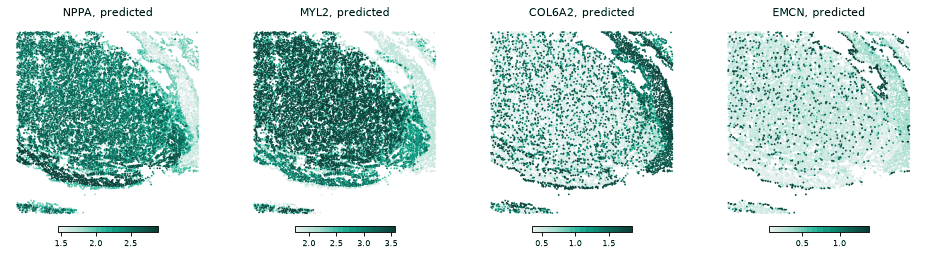

In [6]:
resonate.pl.spatial_genes(pred, ["NPPA", "MYL2", "COL6A2", "EMCN"])

## 7. Predicted expression by cell type

All 13 markers: mean prediction per cell group of the section (left) next to the measured mean per cell type of the
reference (right). Each row is scaled from its lowest (light) to its highest (dark) group.

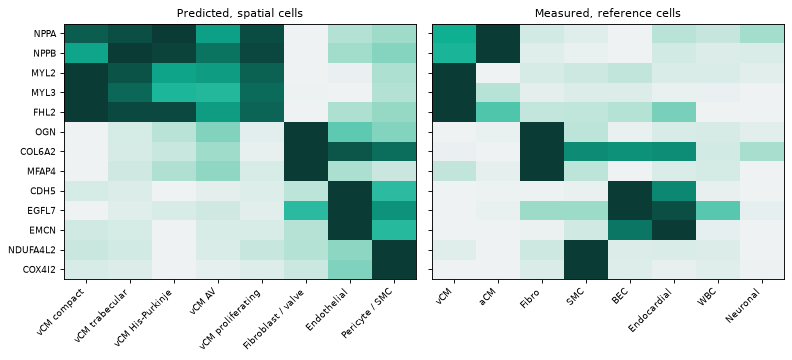

In [7]:
resonate.pl.celltype_heatmap(pred, spatial, "cell_group", markers, reference=reference, reference_groupby="author_label",
                             reference_groups=["vCM", "aCM", "Fibro", "SMC", "BEC", "Endocardial", "WBC", "Neuronal"])

## 8. Save

Predictions are AnnData objects. The model is saved with the prepared inputs it was trained on (reloading: see the
[FAQ](https://j041120h.github.io/RESONATE_tutorial/faq/)).

In [8]:
pred.write_h5ad("predictions.h5ad")
model.save("model")
model.prepared.save("prepared")

**Next:** the same steps from a shell ([command line](https://j041120h.github.io/RESONATE_tutorial/tutorials/cli/)); your own data
([inputs and outputs](https://j041120h.github.io/RESONATE_tutorial/tutorials/inputs_outputs/), [choosing a reference and embeddings](https://j041120h.github.io/RESONATE_tutorial/tutorials/choosing/));
all functions ([API reference](https://j041120h.github.io/RESONATE_tutorial/api/)).